-------
## Projekt - Wstęp do Uczenia Maszynowego

## Kod KM1

-------


### *Import pakietów*

-------

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.tree import DecisionTreeClassifier

### *1. Eksploracyjna analiza danych*
-------

In [3]:
df_X = pd.read_csv('X_train.csv')
df_y = pd.read_csv('y_train.csv')
df_test = pd.read_csv('X_test.csv')

In [4]:
df = pd.merge(df_X, df_y, left_index=True, right_index=True)
print(df_X.shape, df_y.shape, df.shape)

target = 'default.payment.next.month'
cat_cols = ['SEX', 'EDUCATION', 'MARRIAGE']
pay_cols = ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
bill_cols = ['BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6']
pay_amt_cols = ['PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']
amount_cols = ['LIMIT_BAL'] + bill_cols + pay_amt_cols
numeric_cols = ['AGE', 'LIMIT_BAL'] + pay_cols + bill_cols + pay_amt_cols

(6400, 23) (6400, 1) (6400, 24)


### *1.1 Statystyki opisowe i typy zmiennych*
-------

In [5]:
df.head()

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,19912.825563,2,2,1,44,2,0,0,2,2.0,...,17974.686955,18841.431580,15783.245882,1423.110120,3049.157007,157.071859,733.154414,478.947062,379.984156,1
1,55043.974658,1,1,2,24,4,4,4,4,3.0,...,38224.238356,39238.101886,40576.008942,2037.243581,1854.121994,300.752767,1020.891555,-455.518882,2469.448131,0
2,20006.277688,2,2,2,31,0,0,0,0,NaN,...,28966.654890,19049.390827,15402.347969,10175.669342,4573.613449,-771.581797,-283.002435,4857.385369,3474.203409,0
3,128698.125632,1,1,2,31,-1,-1,-1,-2,-2.0,...,-2834.834778,-786.605171,49261.032919,10858.685707,1101.369070,25.587625,-331.783255,49191.348594,3767.305856,0
4,358711.329669,2,1,1,34,-2,-2,-2,-2,-2.0,...,16441.809554,14173.086443,21134.235164,6945.506312,691.104497,7333.776096,5973.950428,5218.051932,28455.969902,0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6400 entries, 0 to 6399
Data columns (total 24 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   LIMIT_BAL                   6400 non-null   float64
 1   SEX                         6400 non-null   int64  
 2   EDUCATION                   6400 non-null   int64  
 3   MARRIAGE                    6400 non-null   int64  
 4   AGE                         6400 non-null   int64  
 5   PAY_0                       6400 non-null   int64  
 6   PAY_2                       6400 non-null   int64  
 7   PAY_3                       6400 non-null   int64  
 8   PAY_4                       6400 non-null   int64  
 9   PAY_5                       5764 non-null   float64
 10  PAY_6                       6400 non-null   int64  
 11  BILL_AMT1                   6400 non-null   float64
 12  BILL_AMT2                   6400 non-null   float64
 13  BILL_AMT3                   6400 

Wszystkie kolumny są liczbowe.

`PAY_5` ma typ `float` tylko dlatego, że zawiera braki: wszystkie jej wartości są całkowite. Numeracja jest niespójna: nie ma `PAY_1`, więc najświeższy miesiąc to `PAY_0`, ale `BILL_AMT1` i `PAY_AMT1`.

In [7]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,6400.0,167058.28,130788.62,-157.51,54027.84,138508.70,236847.70,783258.37
SEX,6400.0,1.60,0.49,1.00,1.00,2.00,2.00,2.00
EDUCATION,6400.0,1.84,0.80,0.00,1.00,2.00,2.00,6.00
MARRIAGE,6400.0,1.57,0.52,0.00,1.00,2.00,2.00,3.00
AGE,6400.0,34.83,9.09,19.00,28.00,33.00,41.00,73.00
PAY_0,6400.0,-0.02,1.13,-2.00,-1.00,0.00,0.00,8.00
PAY_2,6400.0,-0.15,1.18,-2.00,-1.00,0.00,0.00,7.00
PAY_3,6400.0,-0.17,1.19,-3.00,-1.00,0.00,0.00,7.00
PAY_4,6400.0,-0.23,1.16,-2.00,-1.00,0.00,0.00,7.00
PAY_5,5764.0,-0.28,1.12,-2.00,-1.00,0.00,0.00,7.00


Z tabeli wynikają cztery obserwacje:

- `PAY_AMT*` są mocno prawoskośne: średnia `PAY_AMT1` to 5916, a mediana tylko 2489.
- Średni rachunek rośnie w stronę najświeższego miesiąca.
- Minima pokazują wartości niemożliwe lub podejrzane: `LIMIT_BAL` = -157,51, `PAY_3` = -3 oraz ujemne `PAY_AMT*`.
- `BILL_AMT6` ma minimum -233 710, znacznie niższe niż pozostałe `BILL_AMT` (najniższe z nich to -55 475).

In [8]:
print(df.EDUCATION.value_counts().sort_index(), '\n')
print(df.MARRIAGE.value_counts().sort_index(), '\n')
print(df[target].value_counts(normalize=True).round(4))

EDUCATION
0       4
1    2352
2    2910
3    1030
4      29
5      69
6       6
Name: count, dtype: int64 

MARRIAGE
0      11
1    2824
2    3501
3      64
Name: count, dtype: int64 

default.payment.next.month
0    0.7842
1    0.2158
Name: proportion, dtype: float64


Wartości 0, 4, 5, 6 w `EDUCATION` oraz 0, 3 w `MARRIAGE` są rzadkie, ale to nie są ukryte braki danych: opis zbioru definiuje je jako kategorię „inne”.

Klasy są niezbalansowane: 21,6% klientów to klasa 1. Model, który zawsze przewiduje 0, osiągnąłby accuracy 78,4%, więc accuracy nie będzie dobrą metryką.

### *1.2 Rozkłady zmiennych*
-------

**1.2.1 Zmienne kategoryczne i zmienna docelowa**

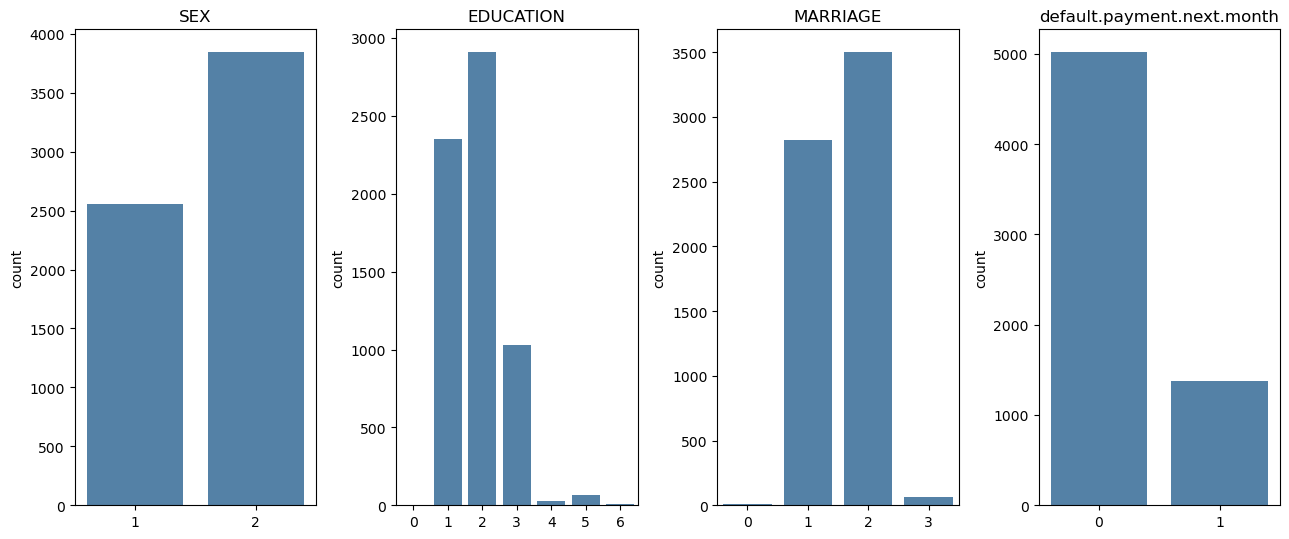

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(13, 5.5))
for ax, col in zip(axes, cat_cols + [target]):
    sns.countplot(data=df, x=col, ax=ax, color='steelblue')
    ax.set_title(col)
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

Kobiety stanowią ok. 60% klientów. Dominują dwie kategorie wykształcenia (1 i 2) oraz dwa stany cywilne (1 i 2), a grupy „inne” są bardzo małe: 108 osób w `EDUCATION` i 75 w `MARRIAGE`.

**1.2.2 Historia spłat `PAY_*`**

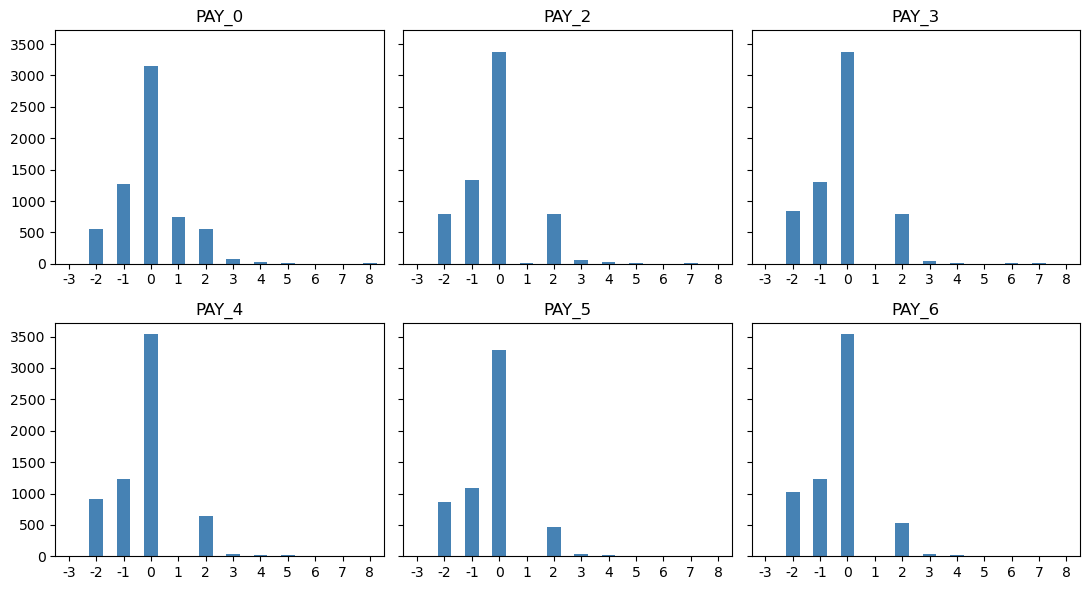

,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6
-3,0,0,1,0,0,0
-2,561,786,837,911,867,1031
-1,1270,1331,1302,1238,1080,1235
0,3148,3379,3378,3540,3279,3542
1,752,10,0,0,1,1
2,555,792,796,636,473,524
3,71,65,52,34,30,37
4,25,27,18,14,14,14
5,9,5,2,13,9,3
6,4,0,8,3,0,1


In [10]:
pay_counts = pd.DataFrame({col: df[col].value_counts() for col in pay_cols}).sort_index().fillna(0).astype(int)
pay_counts.index = pay_counts.index.astype(int)

fig, axes = plt.subplots(2, 3, figsize=(11, 6), sharey=True)
for ax, col in zip(axes.ravel(), pay_cols):
    pay_counts[col].plot.bar(ax=ax, color='steelblue', rot=0)
    ax.set_title(col)
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

pay_counts

W pdf nie ma opisu więc coś takiego znalazłem w internecie: -2 to brak zadłużenia, -1 terminowa spłata, 0 korzystanie z kredytu odnawialnego ze spłatą minimum, a wartości dodatnie to liczba miesięcy opóźnienia.

Większość klientów ma w każdym miesiącu status 0, -1 lub -2, a opóźnienia od 3 miesięcy są rzadkie. Wartość 1 występuje prawie wyłącznie w `PAY_0` (752 razy, a w pozostałych kolumnach od 0 do 10 razy), co sugeruje inny sposób kodowania tej kolumny. `PAY_3` zawiera jedną wartość -3, która nie pasuje do skali, pewnie ktoś missclicka zrobił zamiast -2 D:

**1.2.3 Zmienne ciągłe(no dyskretne w sumie też)**

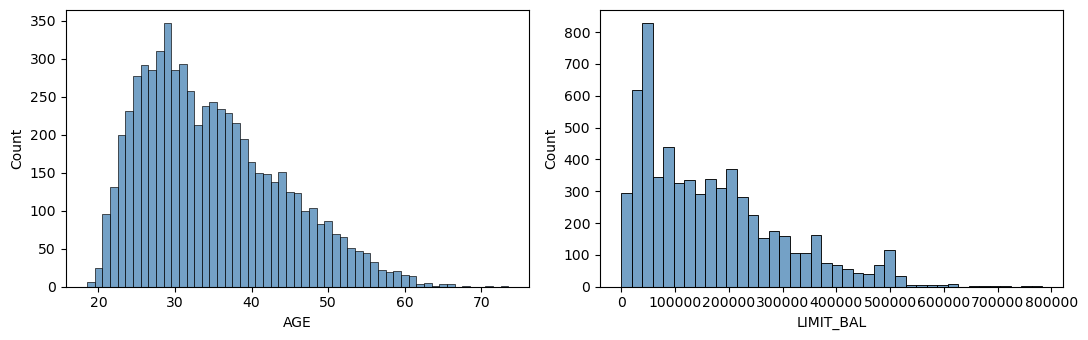

Skośność zmiennych numerycznych:


AGE           0.68
LIMIT_BAL     1.02
BILL_AMT1     2.65
BILL_AMT2     2.64
BILL_AMT3     2.68
BILL_AMT4     2.73
BILL_AMT5     2.71
BILL_AMT6     2.66
PAY_AMT1      8.89
PAY_AMT2     12.16
PAY_AMT3     10.00
PAY_AMT4     11.91
PAY_AMT5     10.25
PAY_AMT6     11.54
dtype: float64

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(df['AGE'], discrete=True, ax=axes[0], color='steelblue')
sns.histplot(df['LIMIT_BAL'], bins=40, ax=axes[1], color='steelblue')
plt.tight_layout()
plt.show()
print('Skośność zmiennych numerycznych:')
df[numeric_cols].drop(columns=pay_cols).skew().round(2)

`AGE` mieści się w zakresie 19–73 lata, z medianą 33 i lekką prawoskośnością. `LIMIT_BAL` ma piki w okolicach okrągłych kwot, np. 50 000, 200 000 i 500 000, co wskazuje, że limity przyznawane są progami.

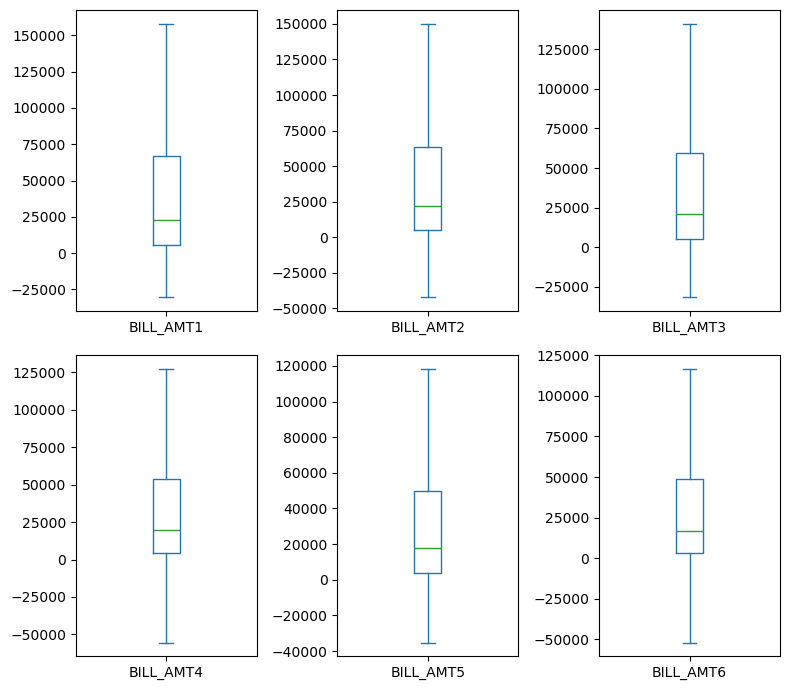

In [12]:
df[bill_cols].plot.box(
    subplots=True, figsize=(8, 7), layout=(2, 3), sharex=False, sharey=False, showfliers=False)
plt.tight_layout()
plt.show()

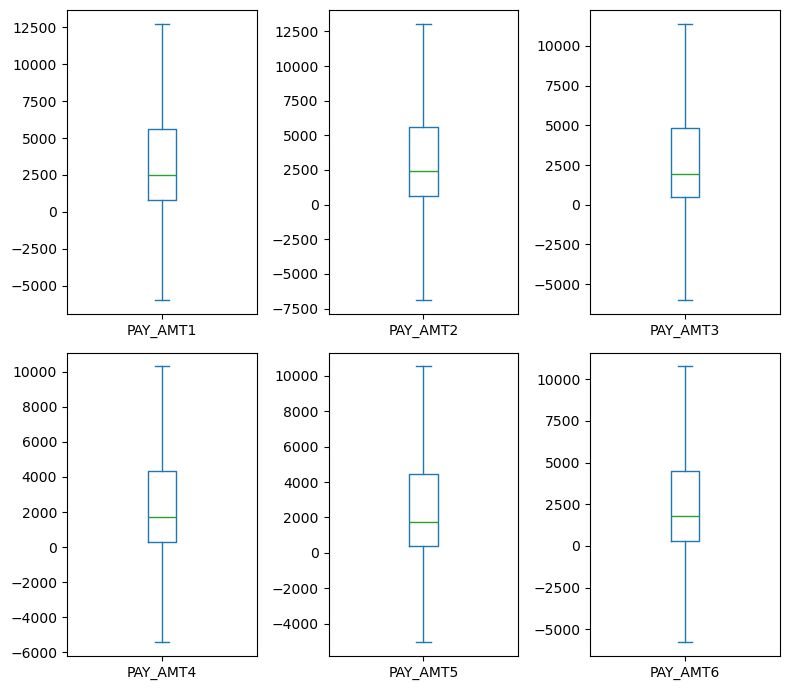

In [13]:
df[pay_amt_cols].plot.box(
    subplots=True, figsize=(8, 7), layout=(2, 3), sharex=False, sharey=False, showfliers=False)
plt.tight_layout()
plt.show()

Na tych boxplotach celowo ukrywam punkty odstające (`showfliers=False`), aby było widać środek rozkładów.

### *1.3 Wartości brakujące*
-------

In [14]:
missing = pd.DataFrame({
    'braki': df_X.isna().sum(),
    'train_%': df_X.isna().mean().mul(100).round(2),
    'test_%': df_test.isna().mean().mul(100).round(2),
})
missing = missing[missing['braki'] > 0]
print('Wiersze z co najmniej 1 brakiem: {:.2%}'.format(df_X.isna().any(axis=1).mean()))
print('Wiersze z co najmniej 2 brakami: {:.2%}'.format((df_X.isna().sum(axis=1) >= 2).mean()))
missing

Wiersze z co najmniej 1 brakiem: 27.23%
Wiersze z co najmniej 2 brakami: 2.72%


,braki,train_%,test_%
PAY_5,636,9.94,10.25
BILL_AMT6,653,10.20,9.19
PAY_AMT4,635,9.92,10.31


### *1.4 Wartości niemożliwe i odstające*
-------

 **1.4.1 Wartości niemożliwe**

In [15]:
print('LIMIT_BAL <= 0:', (df['LIMIT_BAL'] <= 0).sum(), '| min =', round(df['LIMIT_BAL'].min(), 2))
print('PAY_* < -2:', (df[pay_cols] < -2).sum().to_dict())
negatives = pd.DataFrame({
    'train_%': df[amount_cols].lt(0).mean().mul(100).round(2),
    'test_%': df_test[amount_cols].lt(0).mean().mul(100).round(2)})
negatives

LIMIT_BAL <= 0: 1 | min = -157.51
PAY_* < -2: {'PAY_0': 0, 'PAY_2': 0, 'PAY_3': 1, 'PAY_4': 0, 'PAY_5': 0, 'PAY_6': 0}


,train_%,test_%
LIMIT_BAL,0.02,0.00
BILL_AMT1,13.02,13.50
BILL_AMT2,13.64,13.75
BILL_AMT3,14.11,14.31
BILL_AMT4,14.48,14.12
BILL_AMT5,14.62,14.06
BILL_AMT6,13.91,13.88
PAY_AMT1,14.37,14.19
PAY_AMT2,17.69,18.44
PAY_AMT3,16.95,16.88


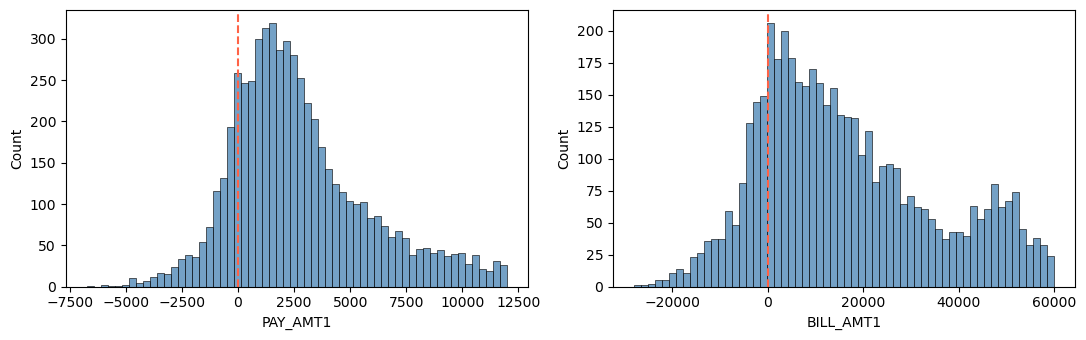

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
#pomijamy wartości skrajne, żeby histogramy były bardziej czytelne
sns.histplot(df.loc[df['PAY_AMT1'].between(-8000, 12000), 'PAY_AMT1'], bins=60, ax=axes[0], color='steelblue')
sns.histplot(df.loc[df['BILL_AMT1'].between(-30000, 60000), 'BILL_AMT1'], bins=60, ax=axes[1], color='steelblue')
for ax in axes:
    ax.axvline(0, color='tomato', linestyle='--')
plt.tight_layout()
plt.show()

Pojedyncze wartości niemożliwe to `LIMIT_BAL` = -157,51 oraz `PAY_3` = -3 (po jednym wierszu). Znacznie większy 'problem' to ujemne kwoty.

**1.4.2 Wartości odstające**

In [17]:
q1, q3 = df[amount_cols].quantile(0.25), df[amount_cols].quantile(0.75)
iqr = q3 - q1
low, high = df[amount_cols] < q1 - 1.5 * iqr, df[amount_cols] > q3 + 1.5 * iqr

pd.DataFrame({
    'outliery_%': (low | high).mean().mul(100).round(2),
    'q99': df[amount_cols].quantile(0.99).round(0),
    'default_wysokie': [df.loc[high[col], target].mean() for col in amount_cols],
    'default_reszta': [df.loc[~high[col], target].mean() for col in amount_cols],
}).round(3)

,outliery_%,q99,default_wysokie,default_reszta
LIMIT_BAL,0.98,510917.0,0.175,0.216
BILL_AMT1,8.08,352831.0,0.195,0.218
BILL_AMT2,8.55,335607.0,0.194,0.218
BILL_AMT3,8.98,328088.0,0.193,0.218
BILL_AMT4,9.22,295257.0,0.192,0.218
BILL_AMT5,9.27,272626.0,0.199,0.217
BILL_AMT6,8.45,265355.0,0.186,0.219
PAY_AMT1,8.80,70089.0,0.135,0.224
PAY_AMT2,8.89,77750.0,0.096,0.227
PAY_AMT3,9.16,77992.0,0.142,0.223


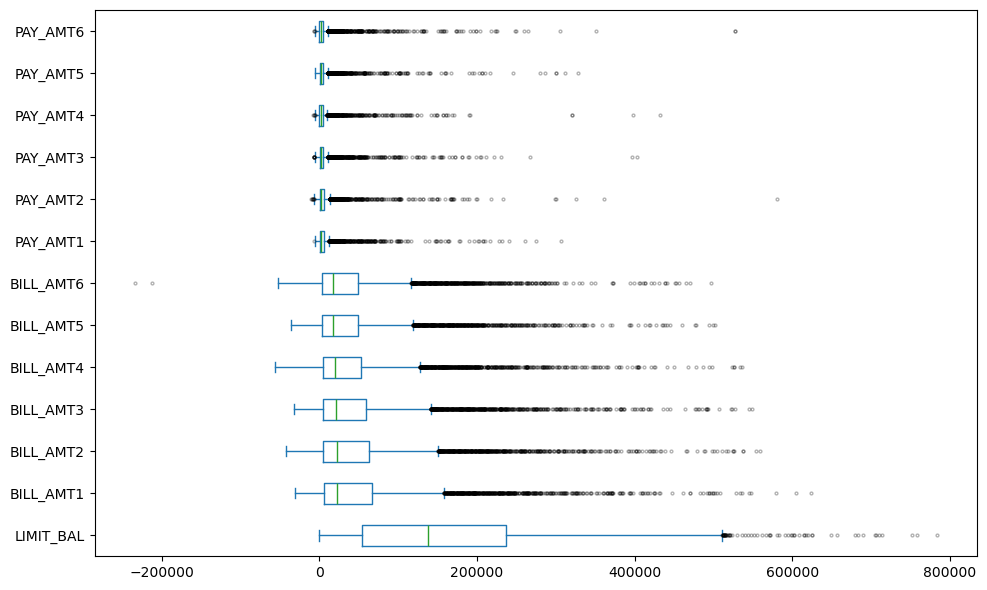

In [18]:
df[amount_cols].plot.box(vert=False, figsize=(10, 6), flierprops={'markersize': 2, 'alpha': 0.3})
plt.tight_layout()
plt.show()

### *1.5 Relacje i istotność zmiennych*
-------

**1.5.1 Korelacje między zmiennymi**

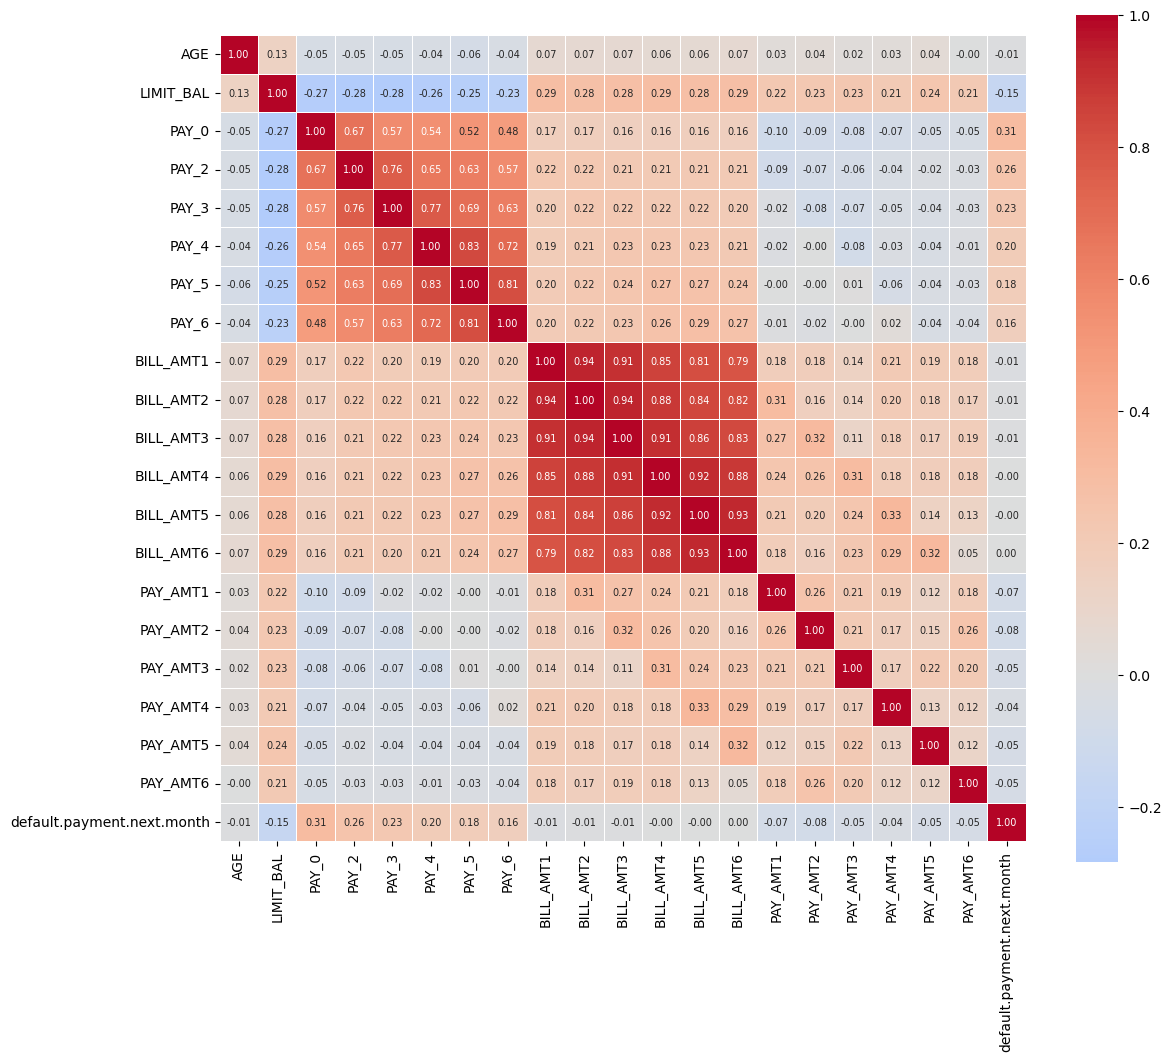

In [19]:
plt.figure(figsize=(13, 11))
sns.heatmap(df[numeric_cols + [target]].corr(), annot=True, fmt='.2f', cmap='coolwarm',
            center=0, cbar=True, square=True, linewidths=0.5, annot_kws={'size': 7})
plt.show()

Zmienne z tej samej grupy są silnie powiązane: `BILL_AMT*` ,a `PAY_*`, najmocniej w sąsiednich miesiącach. 

**1.5.3 Odsetek defaultów w kategoriach**

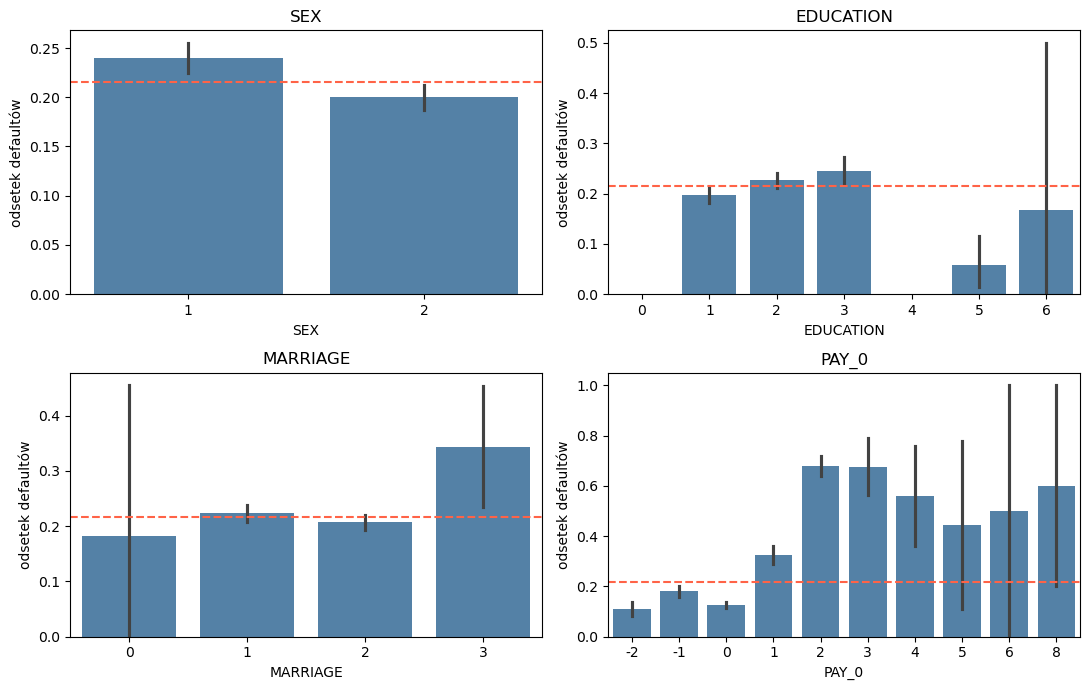

     mean  size
SEX            
1    0.24  2555
2    0.20  3845 

            mean  size
EDUCATION             
0          0.000     4
1          0.197  2352
2          0.227  2910
3          0.245  1030
4          0.000    29
5          0.058    69
6          0.167     6 

           mean  size
MARRIAGE             
0         0.182    11
1         0.224  2824
2         0.207  3501
3         0.344    64 

        mean  size
PAY_0             
-2     0.109   561
-1     0.180  1270
 0     0.127  3148
 1     0.324   752
 2     0.679   555
 3     0.676    71
 4     0.560    25
 5     0.444     9
 6     0.500     4
 8     0.600     5 



In [20]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), cat_cols + ['PAY_0']):
    sns.barplot(data=df, x=col, y=target, ax=ax, color='steelblue', seed=42)
    ax.axhline(df[target].mean(), color='tomato', linestyle='--')
    ax.set_ylabel('odsetek defaultów')
    ax.set_title(col)
plt.tight_layout()
plt.show()

for col in cat_cols + ['PAY_0']:
    print(df.groupby(col)[target].agg(['mean', 'size']).round(3), '\n')

Czerwona linia to średni odsetek defaultów.

- `PAY_0` wyraźnie dzieli klientów.
- `SEX`: mężczyźni mają 24,0% defaultów, a kobiety 20,0%.
- `EDUCATION`: odsetek rośnie od 19,7% (1) przez 22,7% (2) do 24,5% (3). Kategoria „inne” ma łącznie tylko 4,6% (108 osób), choć grupa jest mała.
- `MARRIAGE`: grupy 1 i 2 są zbliżone (22,4% i 20,7%), a „inne” ma 32,0% (75 osób).

**1.5.4 Zmienne ciągłe a default**

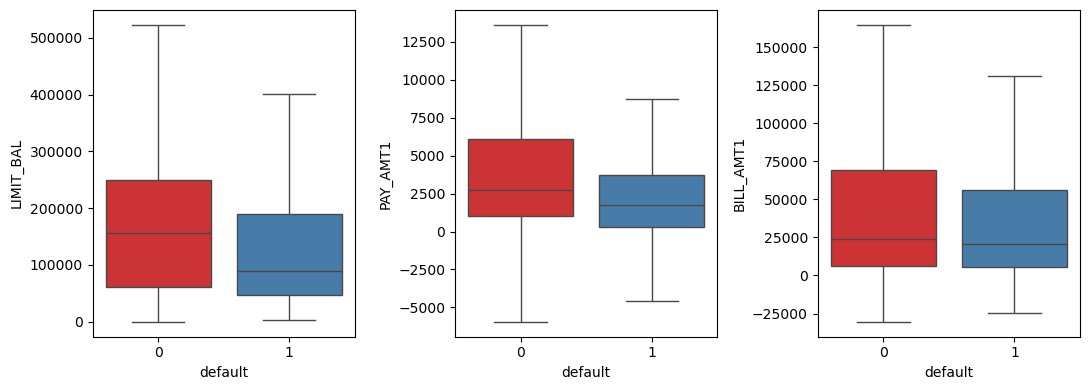

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(11, 4))
for ax, col in zip(axes, ['LIMIT_BAL', 'PAY_AMT1', 'BILL_AMT1']):
    sns.boxplot(data=df, x=target, y=col, hue=target, palette='Set1', legend=False, ax=ax, showfliers=False)
    ax.set_xlabel('default')
plt.tight_layout()
plt.show()

Klienci z defaultem mają niższy limit (mediana ok. 90 000 wobec ok. 155 000) i niższą wpłatę w ostatnim miesiącu, a mediany `BILL_AMT1` są zbliżone.

### *1.6 Podsumowanie analizy danych*
-------

**Najważniejsze wnioski:**

- Klasy są niezbalansowane (21,6% klasy 1), więc accuracy nie będzie dobrą metryką.
- Najbardziej informacyjne są świeże statusy spłaty, zwłaszcza `PAY_0`, a następnie `LIMIT_BAL` i `PAY_AMT*`.
- Zależności są nieliniowe

### *2. Metryka ewaluacji i podział danych*
-------

Wybieram **ROC AUC**. Klasy są niezbalansowane, więc accuracy nic nie mówi, bo model zawsze przewidujący 0 ma ok. 78%. ROC AUC ocenia, jak dobrze model ustawia klientów od najmniej do najbardziej ryzykownych.

In [22]:
X = df.drop(columns=target)
y = df[target]

print('Accuracy modelu "zawsze 0":', round(1 - y.mean(), 4))
print('ROC AUC modelu "zawsze 0":', roc_auc_score(y, np.zeros(len(y))))

Accuracy modelu "zawsze 0": 0.7842
ROC AUC modelu "zawsze 0": 0.5


### *2.1 Podział danych*
-------

Nie ma `y_test`. Robię podział:

- 80% na zbiór treningowy 
- 20% na zbiór walidacyjny 

In [23]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

print(X_train.shape, X_val.shape)

(5120, 23) (1280, 23)


### *3. Optymalizacja hiperparametrów drzewa decyzyjnego*
-------

Stroję trzy hiperparametry:

- max_depth
- min_samples_leaf
- criterion

In [24]:
max_depths = [2, 3, 4, 5, 6, 8, 10, 15, 25]
min_samples_leafs = [1, 5, 10, 25, 50, 100, 200]
criterions = ['gini', 'entropy']

rows = []
#coś w stylu co na zajęciach by znaleźć najlepsze parametry modelu
for max_depth in max_depths:
    for min_samples_leaf in min_samples_leafs:
        for criterion in criterions:
            model = DecisionTreeClassifier(max_depth=max_depth, min_samples_leaf=min_samples_leaf,
                                           criterion=criterion, random_state=42)
            scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc')
            model.fit(X_train, y_train)
            rows.append({
                'max_depth': max_depth,
                'min_samples_leaf': min_samples_leaf,
                'criterion': criterion,
                'auc_cv': scores.mean(),
                'auc_trening': roc_auc_score(y_train, model.predict_proba(X_train)[:, 1]),
            })

results = pd.DataFrame(rows)
best = results.loc[results['auc_cv'].idxmax()]

print('Liczba kombinacji:', len(results))
print('Najlepsze parametry:', best[['max_depth', 'min_samples_leaf', 'criterion']].to_dict())
print('Najlepsze ROC AUC w CV:', round(best['auc_cv'], 4))
print(results.groupby('criterion')['auc_cv'].max().round(4))

Liczba kombinacji: 126
Najlepsze parametry: {'max_depth': 10, 'min_samples_leaf': 100, 'criterion': 'gini'}
Najlepsze ROC AUC w CV: 0.7303
criterion
entropy    0.7288
gini       0.7303
Name: auc_cv, dtype: float64


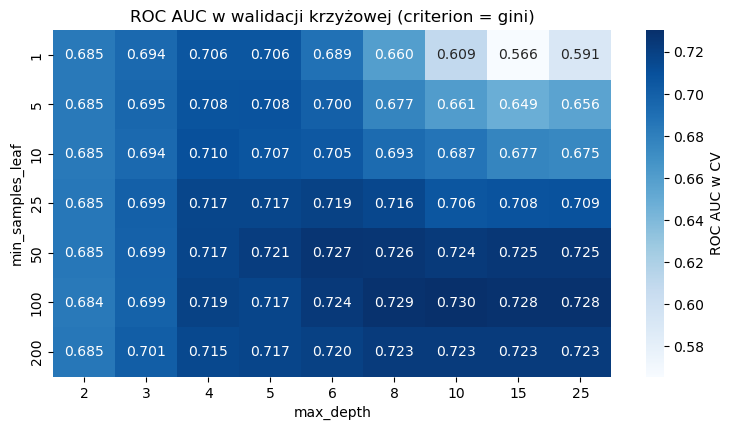

In [25]:
best_criterion = best['criterion']
best_results = results[results['criterion'] == best_criterion]
auc_table = best_results.pivot(index='min_samples_leaf', columns='max_depth', values='auc_cv')

plt.figure(figsize=(9, 4.5))
sns.heatmap(auc_table, annot=True, fmt='.3f', cmap='Blues', cbar_kws={'label': 'ROC AUC w CV'})
plt.xlabel('max_depth')
plt.ylabel('min_samples_leaf')
plt.title(f'ROC AUC w walidacji krzyżowej (criterion = {best_criterion})')
plt.show()

Najlepsza kombinacja to `max_depth = 10`, `min_samples_leaf = 100` i `criterion = gini`, z ROC AUC 0,730.

Najbardziej liczy się `min_samples_leaf`: przy głębokości 25 AUC rośnie z 0,591 (liść 1) do 0,728 (liść 100).

**Ocena na zbiorze walidacyjnym**

In [26]:
default_tree = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
best_tree = DecisionTreeClassifier(max_depth=best['max_depth'], min_samples_leaf=best['min_samples_leaf'],
                                   criterion=best['criterion'], random_state=42).fit(X_train, y_train)

comparison = pd.DataFrame({
    'drzewo domyślne': {
        'głębokość': default_tree.get_depth(),
        'liście': default_tree.get_n_leaves(),
        'AUC trening': roc_auc_score(y_train, default_tree.predict_proba(X_train)[:, 1]),
        'AUC val': roc_auc_score(y_val, default_tree.predict_proba(X_val)[:, 1]),
    },
    'moje drzewo': {
        'głębokość': best_tree.get_depth(),
        'liście': best_tree.get_n_leaves(),
        'AUC trening': roc_auc_score(y_train, best_tree.predict_proba(X_train)[:, 1]),
        'AUC val': roc_auc_score(y_val, best_tree.predict_proba(X_val)[:, 1]),
    },
}).round(4)
comparison

,drzewo domyślne,moje drzewo
głębokość,31.0000,10.0000
liście,694.0000,39.0000
AUC trening,0.9988,0.7993
AUC val,0.6108,0.7476


Drzewo domyślne jest przeuczone: AUC 0,999 na treningu i tylko 0,611 na zbiorze walidacyjnym. Strojone drzewo ma 39 liści zamiast 694 i osiąga 0,748 na zbiorze walidacyjnym przy 0,799 na treningu, więc znacznie lepiej uogólnia.

### *4. Podsumowanie i wnioski*
-------

Dane mają braki i ujemne kwoty, a najważniejsze cechy to statusy spłaty, zwłaszcza `PAY_0`, oraz `LIMIT_BAL`. Jako metrykę wybrałem ROC AUC, a dane podzieliłem stratyfikowanie na 80% do treningu i 20% na zbiór walidacyjny. Najlepsze drzewo (`max_depth = 10`, `min_samples_leaf = 100`, `gini`) ma ROC AUC 0,748 na zbiorze walidacyjnym, przy 0,611 dla drzewa domyślnego.